In [1]:
import numpy as np
from matplotlib.gridspec import GridSpec
import matplotlib.pyplot as plt
import matplotlib.colors as mcolors
from matplotlib.colors import Normalize

In [2]:
delta_list = [0.3, 0.4, 0.5, 0.6, 0.7, 0.8]
beta_list = [3.5, 4.5, 5.5, 6.5, 7.5, 8.5, 9.5]

In [ ]:
# file = "../Environments/Ants_move/PPO/edge_spen/simulation_results_l0.npz"
# file = "../Environments/Ants_move_rand/PPO/edge_spen/simulation_results_rand_l0.npz"
# file = "../Environments/Ants_move/main_analysis/simulation_results_300_30.npz"
file = "../Environments/Ants_move/main_analysis/simulation_results.npz"

data = np.load(file)
positions = data["positions"]
pheromones = data["pheromones"]

In [4]:
n = 300
eta = 0.01
decay_rate = 0.015
Lx = 32
Ly = 32

def beta_crit(d, s0):
    return 1 + 1/s0 + 2*d + d*s0 + d**2*s0

s0 = (n*eta)/(decay_rate*Lx**2)

In [5]:
def plot_pheromone_field(field, beta_list, delta_list, cmap='YlGnBu', info=False):
    fig = plt.figure(figsize=(6,8))
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)

    vmin = np.min(np.log10(field + 1e-2))
    vmax = np.max(np.log10(field + 1e-2))

    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i,j] = fig.add_subplot(gs[i,j])
            ax[i,j].imshow(
                np.log10(field[len(beta_list)-i-1, j][::-1] + 1e-10),
                cmap=cmap, vmin=vmin, vmax=vmax
            )
            ax[i,j].set_xticks([])
            ax[i,j].set_yticks([])

            if j == 0:
                ax[i,j].set_ylabel(
                    f'{beta_list[len(beta_list)-i-1]}',
                    fontsize=12
                )
            if i == len(beta_list)-1:
                ax[i,j].set_xlabel(
                    f'{delta_list[j]}',
                    fontsize=12
                )

    # Asse globale
    ax_curve = fig.add_subplot(gs[:,:], frameon=False)
    ax_curve.plot(
        delta_list,
        [beta_crit(d, s0) for d in delta_list],
        color='red', linestyle='--', linewidth=2.5
    )
    ax_curve.set_xlim(min(delta_list), max(delta_list))
    ax_curve.set_ylim(min(beta_list), max(beta_list))
    ax_curve.set_xticks([])
    ax_curve.set_yticks([])

    # Label globali
    fig.text(-0.05, 0.51, r'$\beta$', fontsize=18, va='center', rotation='vertical')
    fig.text(0.52, -0.03, r'$\delta$', fontsize=18, ha='center')

    if info:
        fig.text(
            -0.1, 0.51,
            r'decreasing noise $\rightarrow$',
            fontsize=12,
            va='center',
            rotation='vertical'
        )

        fig.text(
            0.52, -0.06,
            r'decreasing sensory capacity $\rightarrow$',
            fontsize=12,
            ha='center'
        )

    plt.tight_layout()
    plt.show()


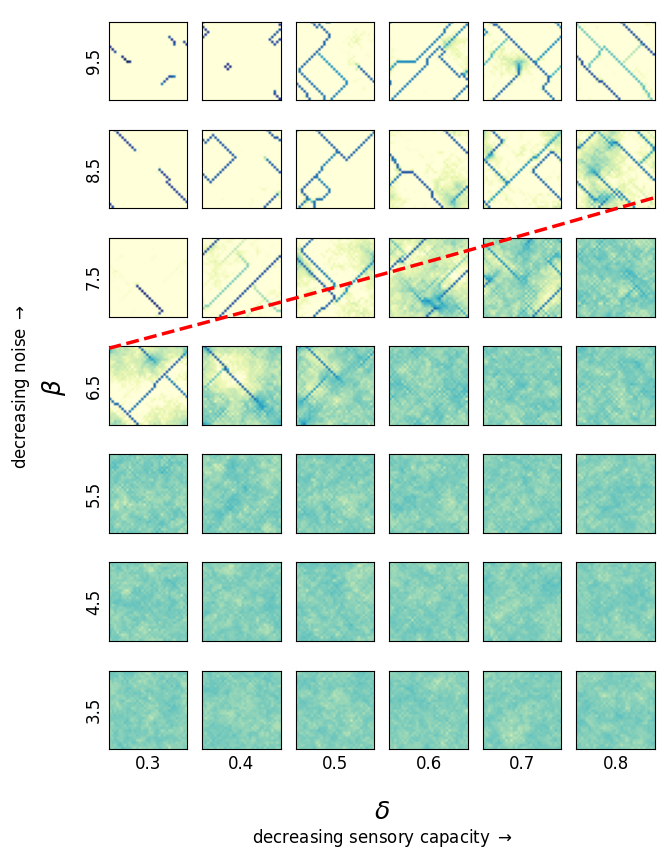

In [6]:
plot_pheromone_field(pheromones, beta_list, delta_list, cmap='YlGnBu', info=True)

In [7]:
def plot_density_field(field, beta_list, delta_list,
                      cmap='binary', info=False):

    fig = plt.figure(figsize=(6,8))
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)

    vmin = np.min(np.log10(field + 1e-1))
    vmax = np.max(np.log10(field + 1e-1))

    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i,j] = fig.add_subplot(gs[i,j])
            ax[i,j].imshow(
                np.log10(field[len(beta_list)-i-1, j][::-1] + 1e-10),
                cmap=cmap, vmin=vmin, vmax=vmax
            )
            ax[i,j].set_xticks([])
            ax[i,j].set_yticks([])

            if j == 0:
                ax[i,j].set_ylabel(
                    f'{beta_list[len(beta_list)-i-1]}',
                    fontsize=12
                )
            if i == len(beta_list)-1:
                ax[i,j].set_xlabel(
                    f'{delta_list[j]}',
                    fontsize=12
                )

    # Asse globale
    ax_curve = fig.add_subplot(gs[:,:], frameon=False)
    ax_curve.plot(
        delta_list,
        [beta_crit(d, s0) for d in delta_list],
        color='red', linestyle='--', linewidth=2.5
    )
    ax_curve.set_xlim(min(delta_list), max(delta_list))
    ax_curve.set_ylim(min(beta_list), max(beta_list))
    ax_curve.set_xticks([])
    ax_curve.set_yticks([])

    # Label globali
    fig.text(-0.05, 0.51, r'$\beta$', fontsize=18,
             va='center', rotation='vertical')
    fig.text(0.52, -0.03, r'$\delta$', fontsize=18,
             ha='center')
    
    if info:
        fig.text(
            -0.1, 0.51,
            r'decreasing noise $\rightarrow$',
            fontsize=12,
            va='center',
            rotation='vertical'
        )

        fig.text(
            0.52, -0.06,
            r'decreasing sensory capacity $\rightarrow$',
            fontsize=12,
            ha='center'
        )

    plt.tight_layout()
    plt.show()


In [8]:
def comput_position_field(positions):
    # converti le posizioni 2D in indici piatti
    flat_idx = (positions[..., 0] * Ly + positions[..., 1]).astype(int)

    # matrice one-hot (N1, N2, N3, Lx*Ly)
    onehot = np.eye(Lx * Ly)[flat_idx]

    # somma lungo la terza asse
    position_field = onehot.sum(axis=2).reshape(
        positions.shape[0], positions.shape[1], Lx, Ly
    )
    return position_field

position_field = comput_position_field(positions)

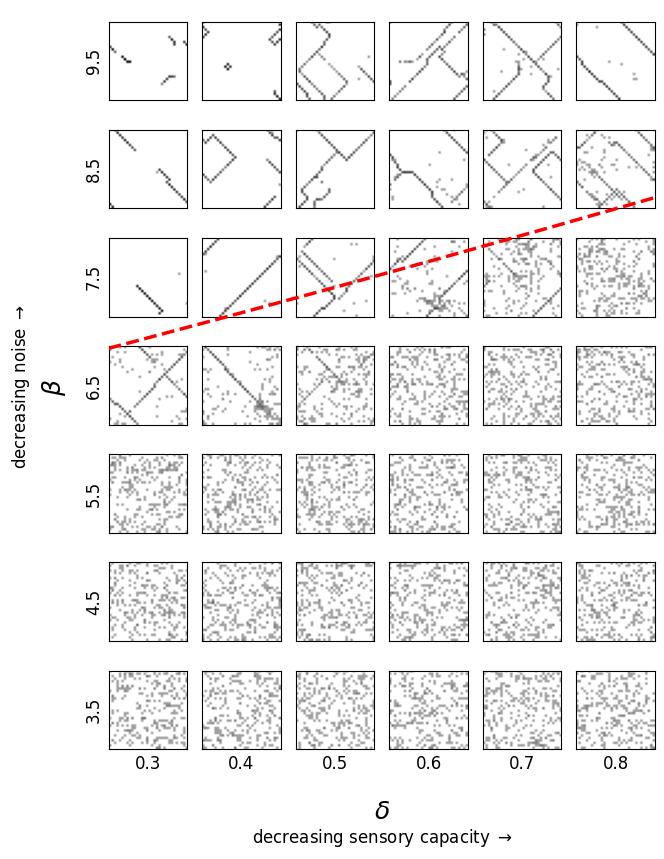

In [9]:
plot_density_field(position_field, beta_list, delta_list, cmap='binary', info=True)

In [10]:
def order_parameter_p(pheromone):
    ns0 = np.mean(pheromone)
    plus_id = pheromone > ns0
    minus_id = pheromone <= ns0
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)

    s_plus = np.sum(pheromone[plus_id])
    s_minus = np.sum(pheromone[minus_id])

    if n_plus == 0 or n_minus == 0:
        return -1
    else:
        local_op = (s_plus - s_minus)/(s_plus + s_minus)
        return local_op
    
order_parameters_p = np.zeros((len(beta_list), len(delta_list)))
for i,beta in enumerate(beta_list):
    for j,delta in enumerate(delta_list):
        order_parameters_p[i,j] = order_parameter_p(pheromones[i,j])

In [11]:
def order_parameter_d(pheromone, position):
    ns0 = np.mean(pheromone)
    plus_id = pheromone > ns0
    minus_id = pheromone <= ns0
    n_plus = np.sum(plus_id)
    n_minus = np.sum(minus_id)
    
    position = np.array(position, dtype=int)
    rho = np.bincount(np.array(position[:,0]*Ly + position[:,1]), minlength=Lx*Ly)
    rho = rho.reshape((Lx, Ly))
    mu_plus = np.sum(rho[plus_id])
    mu_minus = np.sum(rho[minus_id])

    if n_plus == 0 or n_minus == 0:
        return -1
    else:
        local_op = (mu_plus - mu_minus)/(mu_plus + mu_minus)
        return local_op
    
order_parameters_d = np.zeros((len(beta_list), len(delta_list)))
for i,beta in enumerate(beta_list):
    for j,delta in enumerate(delta_list):
        order_parameters_d[i,j] = order_parameter_d(pheromones[i,j], positions[i,j])

In [12]:
def plot_order_parameter(op, beta_list, delta_list,
                         cmap='summer', op_name='pheromone'):

    fig = plt.figure(figsize=(8,8), constrained_layout=True)
    gs = GridSpec(len(beta_list), len(delta_list), figure=fig)

    vmin, vmax = -1, 1
    norm = Normalize(vmin=vmin, vmax=vmax)

    ax = np.empty((len(beta_list), len(delta_list)), dtype=object)

    for i in range(len(beta_list)):
        for j in range(len(delta_list)):
            ax[i, j] = fig.add_subplot(gs[i, j])
            img = ax[i, j].imshow(
                np.ones((1, 1)) * op[len(beta_list)-i-1, j],
                cmap=cmap, norm=norm
            )
            ax[i, j].set_xticks([])
            ax[i, j].set_yticks([])

            if j == 0:
                ax[i, j].set_ylabel(
                    f'{beta_list[len(beta_list)-i-1]}',
                    fontsize=12
                )
            if i == len(beta_list)-1:
                ax[i, j].set_xlabel(
                    f'{delta_list[j]}',
                    fontsize=12
                )

    # Overlay curve
    ax_curve = fig.add_subplot(gs[:, :], frameon=False)
    ax_curve.plot(
        delta_list,
        [beta_crit(d, s0) for d in delta_list],
        color='red', linestyle='--', linewidth=2.5
    )
    ax_curve.set_xlim(min(delta_list), max(delta_list))
    ax_curve.set_ylim(min(beta_list), max(beta_list))
    ax_curve.set_xticks([])
    ax_curve.set_yticks([])

    # Shared colorbar (font!)
    cbar = fig.colorbar(
        img, ax=ax.ravel().tolist(),
        shrink=0.75, pad=0.1
    )
    cbar.ax.tick_params(labelsize=14)

    # Global labels
    fig.text(-0.05, 0.52, r'$\beta$', fontsize=18,
             va='center', rotation='vertical')
    fig.text(0.42, -0.03, r'$\delta$', fontsize=18,
             ha='center')

    plt.show()


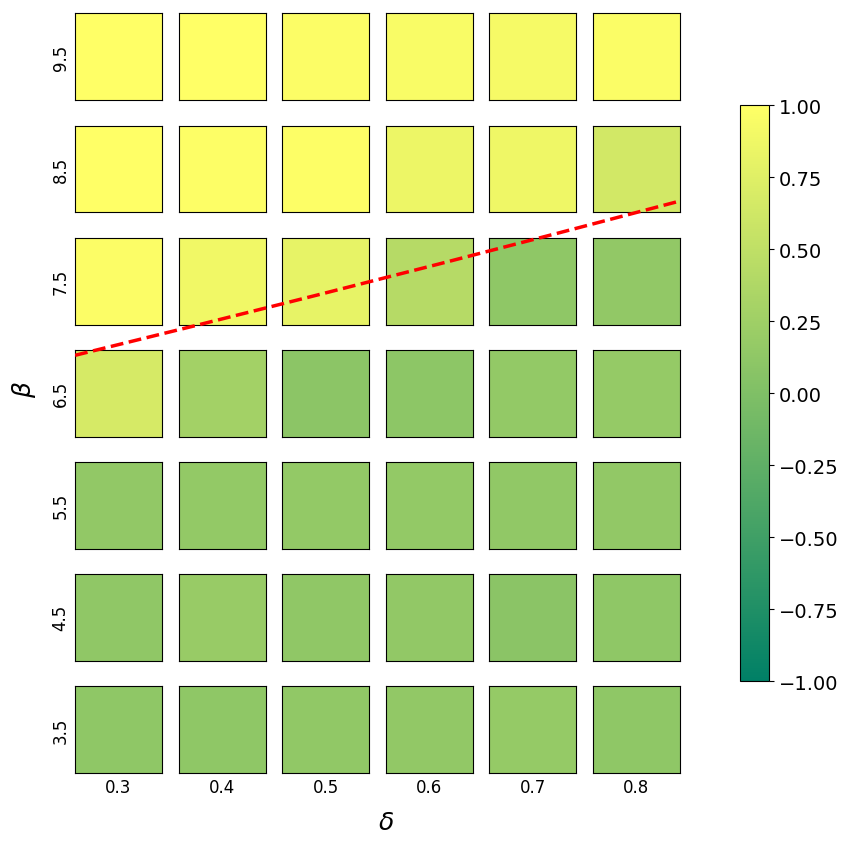

In [13]:
plot_order_parameter(order_parameters_p, beta_list, delta_list, cmap='summer', op_name='Pheromone')

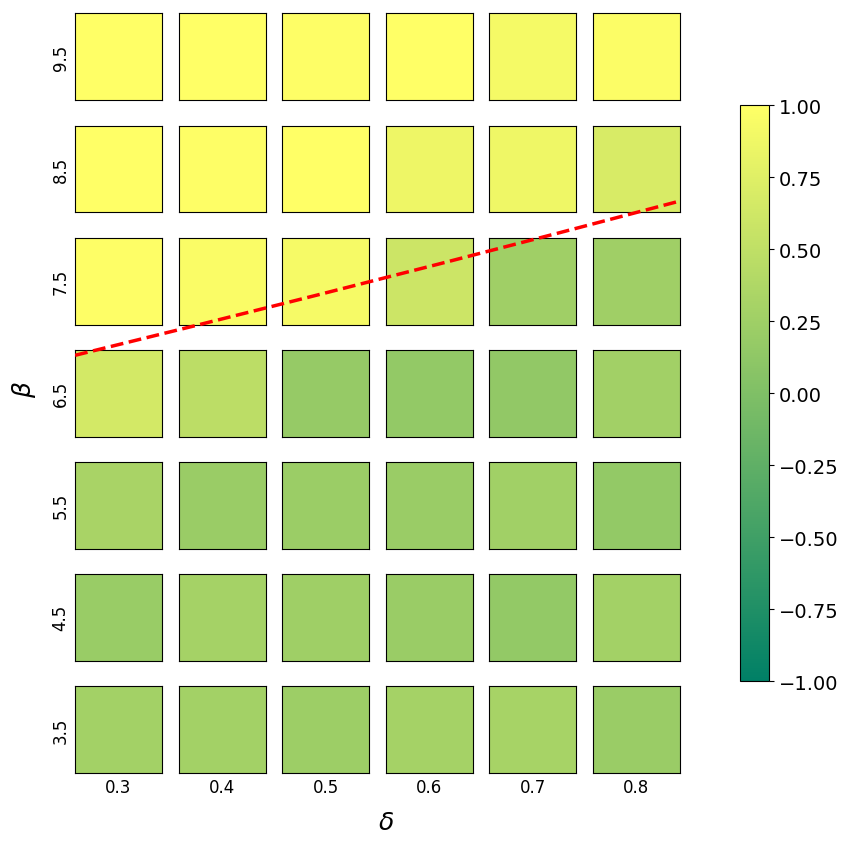

In [14]:
plot_order_parameter(order_parameters_d, beta_list, delta_list, cmap='summer', op_name='Density')